<a href="https://colab.research.google.com/github/CamiMenezes/indentificador-ofensivo/blob/main/03_bertimbau.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip install -q "transformers==4.57.1" "accelerate>=1.1,<2" scikit-learn pandas matplotlib

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [2]:
from google.colab import files
import pandas as pd

enviado = files.upload()
nome = list(enviado.keys())[0]

if nome.endswith(".csv"):
    df = pd.read_csv(nome, sep=None, engine="python")
else:
    df = pd.read_excel(nome)

print(nome)
print(df.shape)
print(df["label final"].value_counts())

Saving hatebr_and_rationales.csv to hatebr_and_rationales.csv
hatebr_and_rationales.csv
(7000, 8)
label final
1.0    3500
0.0    3500
Name: count, dtype: int64


In [3]:
from sklearn.model_selection import train_test_split

df = df.dropna(subset=["comentario", "label final"]).copy()
df["label"] = df["label final"].astype(int)

treino, teste = train_test_split(
    df, test_size=0.2, random_state=42, stratify=df["label"]
)

print("Treino:", len(treino), "| Teste:", len(teste))
print(treino["label"].value_counts())
print(teste["label"].value_counts())

Treino: 5600 | Teste: 1400
label
1    2800
0    2800
Name: count, dtype: int64
label
0    700
1    700
Name: count, dtype: int64


In [4]:
import hashlib
import json
from pathlib import Path
assert len(treino) == 5600 and len(teste) == 1400, "Confira o arquivo enviado."
assert set(df['label'].unique()) == {0, 1}
assert treino.index.intersection(teste.index).empty
treino = treino.copy()
teste = teste.copy()
if 'id' not in df.columns:
    treino['id'] = treino.index
    teste['id'] = teste.index
assert pd.concat([treino['id'], teste['id']]).is_unique, 'IDs precisam ser únicos.'
assinatura_teste = hashlib.sha256(
    teste[['id', 'comentario', 'label']].to_csv(index=False).encode('utf-8')
).hexdigest()
print('SHA256 do teste:', assinatura_teste)
display(teste[['id', 'comentario', 'label']].head())


SHA256 do teste: fbbec0b2fed912e59a21c85d3d2965d84efd2cf726bc5392c565be2fa546dc58


,id,comentario,label
6234,6234,"Volta meu Presidente Bolsonaro, que saudades 🙏...",0
2342,2342,"Esse deputado racista é um verme, verme este q...",1
5698,5698,Foi um desrespeito aos policiais. Policiais sã...,0
5895,5895,A justiça com Lula vai a jato,0
1920,1920,Pegou o virus do molusc a Pepa ta doidaaaaaaa,1


In [5]:
import os
os.environ['WANDB_DISABLED'] = 'true'
import time, platform, subprocess, importlib.metadata
import numpy as np
import torch
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          Trainer, TrainingArguments, set_seed)
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
assert torch.cuda.is_available(), 'Ative a GPU no Colab antes de continuar.'
GPU = torch.cuda.get_device_name(0)
MODELO = 'neuralmind/bert-base-portuguese-cased'
SEMENTE, EPOCAS, TAXA, LOTE, COMPRIMENTO = 42, 3, 2e-5, 16, 128
set_seed(SEMENTE)
print('GPU:', GPU)
print('Memória total (GiB):', round(torch.cuda.get_device_properties(0).total_memory / 2**30, 2))
print('Classes: 0 = não ofensivo; 1 = ofensivo')


GPU: Tesla T4
Memória total (GiB): 14.56
Classes: 0 = não ofensivo; 1 = ofensivo


In [6]:
tokenizador = AutoTokenizer.from_pretrained(MODELO, do_lower_case=False)
inicio_tokenizacao = time.perf_counter()
class ComentariosDataset(torch.utils.data.Dataset):
    def __init__(self, tabela):
        self.tokens = tokenizador(tabela['comentario'].astype(str).tolist(),
                                  truncation=True, padding='max_length',
                                  max_length=COMPRIMENTO)
        self.labels = tabela['label'].to_numpy(dtype=np.int64)
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        item = {k: torch.tensor(v[i]) for k, v in self.tokens.items()}
        item['labels'] = torch.tensor(self.labels[i], dtype=torch.long)
        return item
dados_treino = ComentariosDataset(treino)
tempo_tokenizacao_treino = time.perf_counter() - inicio_tokenizacao
dados_teste = ComentariosDataset(teste)
print('Tokenização do treino (s):', round(tempo_tokenizacao_treino, 2))


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/43.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/647 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

added_tokens.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Tokenização do treino (s): 0.6


In [8]:
set_seed(SEMENTE)
modelo = AutoModelForSequenceClassification.from_pretrained(
    MODELO, num_labels=2,
    id2label={0: 'nao_ofensivo', 1: 'ofensivo'},
    label2id={'nao_ofensivo': 0, 'ofensivo': 1})
argumentos = TrainingArguments(
    output_dir='/content/bertimbau_checkpoints',
    num_train_epochs=EPOCAS, learning_rate=TAXA,
    per_device_train_batch_size=LOTE, per_device_eval_batch_size=LOTE,
    gradient_accumulation_steps=1, weight_decay=0.0,
    warmup_ratio=0.0, lr_scheduler_type='linear', optim='adamw_torch',
    fp16=False, bf16=False, eval_strategy='no', save_strategy='no',
    logging_steps=50, report_to='none', seed=SEMENTE, data_seed=SEMENTE)
treinador = Trainer(model=modelo, args=argumentos, train_dataset=dados_treino,
                    processing_class=tokenizador)
torch.cuda.synchronize()
inicio = time.perf_counter()
resultado_treino = treinador.train()
torch.cuda.synchronize()
tempo_treino = time.perf_counter() - inicio
print(f'Tempo de treino: {tempo_treino:.2f} s ({tempo_treino / 60:.2f} min)')


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at neuralmind/bert-base-portuguese-cased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Step,Training Loss
50,0.570700
100,0.334900
150,0.272100
200,0.250900
250,0.236900
300,0.307900
350,0.232600
400,0.126200
450,0.205900
500,0.143600


Tempo de treino: 364.24 s (6.07 min)


              precision    recall  f1-score   support

Não ofensivo     0.9034    0.9357    0.9193       700
    Ofensivo     0.9333    0.9000    0.9164       700

    accuracy                         0.9179      1400
   macro avg     0.9184    0.9179    0.9178      1400
weighted avg     0.9184    0.9179    0.9178      1400



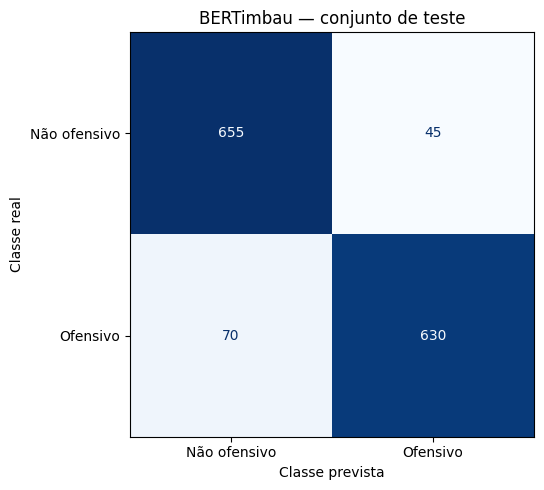

In [9]:
saida = treinador.predict(dados_teste)
predicoes = np.argmax(saida.predictions, axis=1)
reais = teste['label'].to_numpy()
assert np.array_equal(saida.label_ids, reais)
nomes = ['Não ofensivo', 'Ofensivo']
print(classification_report(reais, predicoes, labels=[0, 1],
                            target_names=nomes, digits=4, zero_division=0))
relatorio = classification_report(reais, predicoes, labels=[0, 1],
                                  target_names=nomes, output_dict=True, zero_division=0)
matriz = confusion_matrix(reais, predicoes, labels=[0, 1])
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(matriz, display_labels=nomes).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_xlabel('Classe prevista')
ax.set_ylabel('Classe real')
ax.set_title('BERTimbau — conjunto de teste')
plt.tight_layout()
plt.show()


In [10]:
import zipfile
pasta = Path('/content/results')
pasta.mkdir(exist_ok=True)
previsoes = teste[['id', 'comentario', 'label']].copy()
previsoes['pred_bertimbau'] = predicoes
assert len(previsoes) == 1400 and previsoes['id'].is_unique
previsoes.to_csv(pasta / 'previsoes_bertimbau.csv', index=False)
pd.DataFrame(relatorio).T.to_csv(pasta / 'metricas_bertimbau.csv')
fig.savefig(pasta / 'matriz_confusao_bertimbau.png', dpi=180, bbox_inches='tight')
pacotes = ['torch', 'transformers', 'accelerate', 'numpy', 'pandas', 'scikit-learn', 'matplotlib']
versoes = {p: importlib.metadata.version(p) for p in pacotes}
registro = dict(modelo=MODELO, revisao_modelo=getattr(modelo.config, '_commit_hash', None),
                treino=len(treino), teste=len(teste), gpu=GPU,
                python=platform.python_version(), cuda=torch.version.cuda,
                tempo_treino_segundos=tempo_treino,
                tempo_tokenizacao_treino_segundos=tempo_tokenizacao_treino,
                tempo_treino_mais_tokenizacao_segundos=tempo_treino + tempo_tokenizacao_treino,
                assinatura_teste=assinatura_teste, versoes=versoes,
                comprimento_maximo=COMPRIMENTO, argumentos=argumentos.to_dict(),
                metricas=relatorio, matriz_confusao=matriz.tolist(),
                hardware=subprocess.run(['nvidia-smi'], capture_output=True, text=True).stdout)
(pasta / 'execucao_bertimbau.json').write_text(
    json.dumps(registro, ensure_ascii=False, indent=2, default=str), encoding='utf-8')
(pasta / 'requirements_bertimbau.txt').write_text(
    '\n'.join(f'{p}=={v}' for p, v in versoes.items()) + '\n', encoding='utf-8')
arquivo_zip = '/content/resultados_bertimbau.zip'
with zipfile.ZipFile(arquivo_zip, 'w', zipfile.ZIP_DEFLATED) as z:
    for arquivo in sorted(pasta.glob('*bertimbau*')):
        z.write(arquivo, arquivo.name)
files.download(arquivo_zip)
print('F1 macro:', relatorio['macro avg']['f1-score'])


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

F1 macro: 0.9178309409888357
